# Quarterly revenue analysis

This notebook fits a linear trend to monthly revenue and checks how far each
month is from it. For month $t$ the model is

$$\hat{y}_t = \beta_0 + \beta_1 t, \qquad \hat{\beta} = (X^\top X)^{-1} X^\top y$$

and the residual is $e_t = y_t - \hat{y}_t$.

> [!NOTE]
> December figures are preliminary until the books close.

In [1]:
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sales = pd.read_csv("data/sales.csv", parse_dates=["month"])
print(f"Loaded {len(sales):,} rows from {sales['region'].nunique()} regions")

Loaded 1,204 rows from 4 regions


/opt/conda/lib/python3.12/site-packages/pandas/io/parsers/c_parser_wrapper.py:234: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  chunks = self._reader.read_low_memory(nrows)


In [2]:
summary = (
    sales.groupby("region")[["revenue", "orders"]].sum()
    .assign(avg_order=lambda df: df.revenue / df.orders)
    .sort_values("revenue", ascending=False)
)
summary

,revenue,orders,avg_order
region,,,
North America,312480,2841,109.99
Europe,241935,2209,109.52
Asia Pacific,187320,1876,99.85
Latin America,94610,951,99.48


## Trend

Revenue grew in every region. North America leads, and its average order is
also the largest.

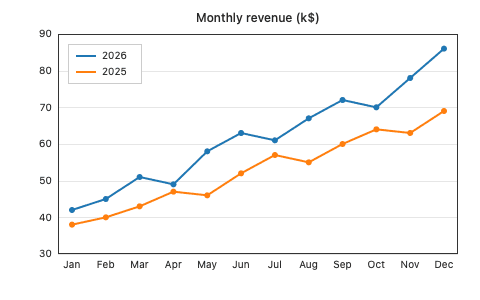

In [3]:
monthly = sales.pivot_table(index=sales.month.dt.month, columns=sales.month.dt.year,
                            values="revenue", aggfunc="sum") / 1000
ax = monthly[[2026, 2025]].plot(marker="o", title="Monthly revenue (k$)", figsize=(4.8, 3))
ax.set_xticks(range(1, 13), calendar.month_abbr[1:])
plt.show()

In [4]:
from IPython.display import Math

slope, intercept = np.polyfit(np.arange(12), monthly[2026], 1)
Math(rf"\hat{{y}}_t = {intercept:.1f} + {slope:.2f}\,t")

<IPython.core.display.Math object>

In [5]:
share = summary.loc["Antarctica", "revenue"] / summary["revenue"].sum()

KeyError: 'Antarctica'

## Next steps

- [x] Fit a linear trend
- [ ] Add a seasonal term
- [ ] Compare regions with `statsmodels`